In [56]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/maternal_aiovy_candidate_6039.csv"
)

features = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "blood_glucose_mmol_l",
    "body_temperature_c",
    "heart_rate"
]

target = "risk_level"

print("Dataset shape:", df.shape)
print("\nMissing values:", df.isna().sum().sum())
print("\nRisk distribution:")
print(df[target].value_counts())

assert len(df) == 6039
assert df[target].nunique() == 3
assert df[features].notna().all().all()

Dataset shape: (6039, 7)

Missing values: 0

Risk distribution:
risk_level
mid risk     2043
low risk     1999
high risk    1997
Name: count, dtype: int64


In [57]:
# Check repeated measurements and conflicting labels

repeated = df.duplicated(subset=features).sum()

groups = df.groupby(features, dropna=False)[target]
conflicts = (groups.nunique() > 1).sum()

print("Repeated feature combinations:", repeated)
print("Conflicting-label groups:", conflicts)

Repeated feature combinations: 548
Conflicting-label groups: 311


In [58]:
# Descriptive upper bound for in-sample accuracy
counts = (
    df.groupby(features + [target], dropna=False)
      .size()
      .unstack(fill_value=0)
)

best_possible_correct = counts.max(axis=1).sum()
accuracy_ceiling = best_possible_correct / len(df)

print("Descriptive in-sample accuracy ceiling:",
      f"{accuracy_ceiling:.2%}")

print("Minimum unavoidable mismatches:",
      len(df) - best_possible_correct)

Descriptive in-sample accuracy ceiling: 94.85%
Minimum unavoidable mismatches: 311


In [59]:
# STEP 4: Inspect groups for leakage-aware splitting

import pandas as pd

group_ids = pd.util.hash_pandas_object(
    df[features],
    index=False
)

print("Total records:", len(df))
print("Unique six-feature groups:", group_ids.nunique())
print("Repeated observations:", len(df) - group_ids.nunique())

group_summary = (
    df.assign(group_id=group_ids)
      .groupby("group_id")
      .agg(
          records=("risk_level", "size"),
          distinct_labels=("risk_level", "nunique")
      )
)

print("\nGroups containing multiple records:",
      (group_summary["records"] > 1).sum())

print("Groups containing conflicting labels:",
      (group_summary["distinct_labels"] > 1).sum())

print("\nGroup sizes:")
display(group_summary["records"].describe())

Total records: 6039
Unique six-feature groups: 5491
Repeated observations: 548

Groups containing multiple records: 432
Groups containing conflicting labels: 311

Group sizes:


count    5491.000000
mean        1.099800
std         0.409209
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         8.000000
Name: records, dtype: float64

In [60]:
from sklearn.model_selection import GroupShuffleSplit

X = df[features]
y = df["risk_level"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=group_ids)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_groups = set(group_ids.iloc[train_idx])
test_groups = set(group_ids.iloc[test_idx])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nOverlapping groups:",
      len(train_groups & test_groups))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training records: 4826
Testing records: 1213

Overlapping groups: 0

Training distribution:
risk_level
mid risk     0.337132
low risk     0.332159
high risk    0.330709
Name: proportion, dtype: float64

Testing distribution:
risk_level
mid risk     0.342951
high risk    0.330585
low risk     0.326463
Name: proportion, dtype: float64


In [61]:
assert len(train_groups & test_groups) == 0
assert len(X_train) + len(X_test) == len(df)

print("Train classes:", sorted(y_train.unique()))
print("Test classes:", sorted(y_test.unique()))

assert y_train.nunique() == 3
assert y_test.nunique() == 3

print("\nSplit validation passed!")

Train classes: ['high risk', 'low risk', 'mid risk']
Test classes: ['high risk', 'low risk', 'mid risk']

Split validation passed!


In [62]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

# Convert risk labels to numbers for XGBoost
encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)

print("Risk labels:", encoder.classes_)
print("Training records:", len(X_train))
print("Testing records (reserved):", len(X_test))

Risk labels: ['high risk' 'low risk' 'mid risk']
Training records: 4826
Testing records (reserved): 1213


In [63]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=2
        ))
    ])
}

print("Baseline models initialized!")

Baseline models initialized!


In [64]:
# Groups for training records only
train_group_ids = group_ids.iloc[train_idx]

# Groups for training and testing
train_group_ids = group_ids.iloc[train_idx]
test_group_ids = group_ids.iloc[test_idx]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

high_risk_code = encoder.transform(["high risk"])[0]

def high_risk_recall(y_true, y_pred):
    return recall_score(
        y_true,
        y_pred,
        labels=[high_risk_code],
        average="macro",
        zero_division=0
    )

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "high_risk_recall": make_scorer(high_risk_recall)
}

results = []

for name, model in models.items():
    print(f"\nTraining: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train_encoded,
        groups=train_group_ids,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Macro F1": scores["test_macro_f1"].mean(),
        "High-Risk Recall": scores[
            "test_high_risk_recall"
        ].mean()
    })

comparison = pd.DataFrame(results)

display(
    comparison.sort_values(
        "High-Risk Recall",
        ascending=False
    ).round(4)
)


Training: Logistic Regression

Training: Random Forest

Training: XGBoost


,Model,Accuracy,Macro F1,High-Risk Recall
1,Random Forest,0.9227,0.9223,0.8596
2,XGBoost,0.9194,0.9187,0.8258
0,Logistic Regression,0.5874,0.5798,0.4574



Generating predictions: Logistic Regression
              precision    recall  f1-score   support

    low risk       0.60      0.79      0.68      1603
    mid risk       0.52      0.51      0.52      1627
   high risk       0.66      0.46      0.54      1596

    accuracy                           0.59      4826
   macro avg       0.59      0.59      0.58      4826
weighted avg       0.59      0.59      0.58      4826



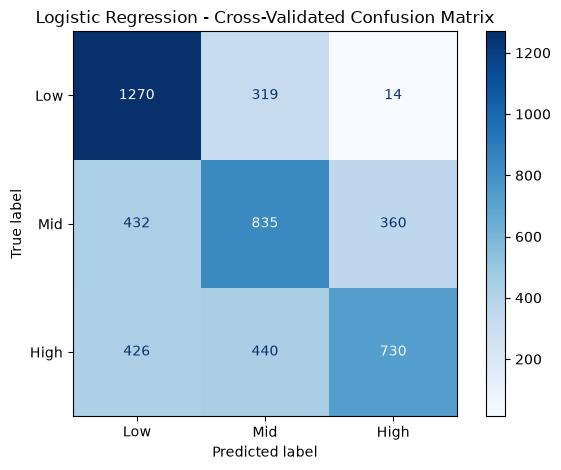


Generating predictions: Random Forest
              precision    recall  f1-score   support

    low risk       0.96      1.00      0.98      1603
    mid risk       0.88      0.91      0.89      1627
   high risk       0.94      0.86      0.90      1596

    accuracy                           0.92      4826
   macro avg       0.92      0.92      0.92      4826
weighted avg       0.92      0.92      0.92      4826



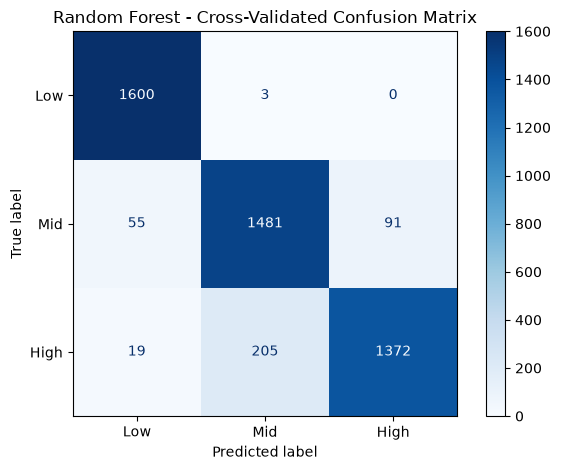


Generating predictions: XGBoost
              precision    recall  f1-score   support

    low risk       0.95      1.00      0.97      1603
    mid risk       0.86      0.93      0.89      1627
   high risk       0.96      0.83      0.89      1596

    accuracy                           0.92      4826
   macro avg       0.92      0.92      0.92      4826
weighted avg       0.92      0.92      0.92      4826



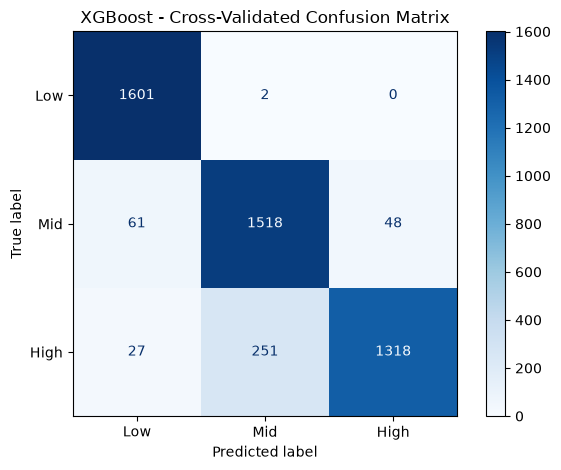

In [65]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Clinical order, not alphabetical order
class_order = ["low risk", "mid risk", "high risk"]

# Convert clinical labels to encoded values
class_codes = encoder.transform(class_order)

cv_predictions = {}

for name, model in models.items():
    print(f"\nGenerating predictions: {name}")

    preds = cross_val_predict(
        model,
        X_train,
        y_train_encoded,
        groups=train_group_ids,
        cv=cv,
        n_jobs=1
    )

    cv_predictions[name] = preds

    print(classification_report(
        y_train_encoded,
        preds,
        labels=class_codes,
        target_names=class_order,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_train_encoded,
        preds,
        labels=class_codes
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low", "Mid", "High"]
    ).plot(cmap="Blues", values_format="d")

    plt.title(f"{name} - Cross-Validated Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [66]:
error_summary = []

high_code = encoder.transform(["high risk"])[0]
low_code = encoder.transform(["low risk"])[0]
mid_code = encoder.transform(["mid risk"])[0]

for name, preds in cv_predictions.items():
    actual_high = y_train_encoded == high_code

    high_to_low = (
        actual_high & (preds == low_code)
    ).sum()

    high_to_mid = (
        actual_high & (preds == mid_code)
    ).sum()

    error_summary.append({
        "Model": name,
        "High → Low": high_to_low,
        "High → Mid": high_to_mid,
        "Total Missed High": high_to_low + high_to_mid
    })

display(
    pd.DataFrame(error_summary)
      .sort_values("Total Missed High")
)

,Model,High → Low,High → Mid,Total Missed High
1,Random Forest,19,205,224
2,XGBoost,27,251,278
0,Logistic Regression,426,440,866


In [67]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

parameter_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 8, 12, 20],
        "model__min_samples_leaf": [1, 2, 4],
        "model__class_weight": [None, "balanced"]
    },

    "XGBoost": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [3, 4, 6],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0]
    }
}

print("Parameter spaces ready!")

Parameter spaces ready!


In [68]:
tuning_results = []
tuned_models = {}

for name, model in models.items():

    print(f"\nTuning {name}...")

    search = RandomizedSearchCV(
        estimator=clone(model),
        param_distributions=parameter_spaces[name],
        n_iter=10,
        scoring=scoring["high_risk_recall"],
        cv=cv,
        random_state=42,
        n_jobs=1,
        verbose=1,
        error_score="raise",
        refit=True
    )

    search.fit(
        X_train,
        y_train_encoded,
        groups=train_group_ids
    )

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV High-Risk Recall": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_table = pd.DataFrame(tuning_results)

display(tuning_table)


Tuning Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Tuning Random Forest...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Tuning XGBoost...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


,Model,Best CV High-Risk Recall,Best Parameters
0,Logistic Regression,0.463656,"{'model__class_weight': 'balanced', 'model__C'..."
1,Random Forest,0.869667,"{'model__n_estimators': 100, 'model__min_sampl..."
2,XGBoost,0.842114,"{'model__subsample': 1.0, 'model__n_estimators..."


In [69]:
from pathlib import Path
import json

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

tuning_table.to_csv(
    reports_dir / "preliminary_tuning_results.csv",
    index=False
)

with open(
    reports_dir / "preliminary_best_parameters.json",
    "w"
) as f:
    json.dump(
        {
            name: result
            for name, result in zip(
                tuning_table["Model"],
                tuning_table["Best Parameters"]
            )
        },
        f,
        indent=2
    )

print("Preliminary tuning results saved!")

Preliminary tuning results saved!


In [70]:
## Phase 5: Preliminary Hyperparameter Tuning

In [71]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

parameter_spaces = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 8, 12, 20],
        "model__min_samples_leaf": [1, 2, 4],
        "model__class_weight": [None, "balanced"]
    },

    "XGBoost": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [3, 4, 6],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0]
    }
}

print("Parameter spaces ready!")

Parameter spaces ready!


In [72]:
import pandas as pd

tuning_results = []
tuned_models = {}

for name, model in models.items():
    print(f"\nTuning {name}...")

    search = RandomizedSearchCV(
        estimator=clone(model),
        param_distributions=parameter_spaces[name],
        n_iter=10,
        scoring=scoring["high_risk_recall"],
        cv=cv,
        random_state=42,
        n_jobs=1,
        verbose=1,
        error_score="raise",
        refit=True
    )

    search.fit(
        X_train,
        y_train_encoded,
        groups=train_group_ids
    )

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV High-Risk Recall": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_table = pd.DataFrame(tuning_results)

display(tuning_table)


Tuning Logistic Regression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Tuning Random Forest...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Tuning XGBoost...
Fitting 5 folds for each of 10 candidates, totalling 50 fits


,Model,Best CV High-Risk Recall,Best Parameters
0,Logistic Regression,0.463656,"{'model__class_weight': 'balanced', 'model__C'..."
1,Random Forest,0.869667,"{'model__n_estimators': 100, 'model__min_sampl..."
2,XGBoost,0.842114,"{'model__subsample': 1.0, 'model__n_estimators..."


In [73]:
from pathlib import Path
import json

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

tuning_table.to_csv(
    reports_dir / "preliminary_tuning_results.csv",
    index=False
)

with open(
    reports_dir / "preliminary_best_parameters.json",
    "w"
) as f:
    json.dump(
        dict(zip(
            tuning_table["Model"],
            tuning_table["Best Parameters"]
        )),
        f,
        indent=2
    )

print("Preliminary tuning results saved!")

Preliminary tuning results saved!


In [74]:
print("PRELIMINARY TUNING RESULTS")

display(
    tuning_table[
        ["Model", "Best CV High-Risk Recall"]
    ].sort_values(
        "Best CV High-Risk Recall",
        ascending=False
    ).round(4)
)

print("\nBEST HYPERPARAMETERS")

for name, params in zip(
    tuning_table["Model"],
    tuning_table["Best Parameters"]
):
    print(f"\n{name}:")
    print(params)

PRELIMINARY TUNING RESULTS


,Model,Best CV High-Risk Recall
1,Random Forest,0.8697
2,XGBoost,0.8421
0,Logistic Regression,0.4637



BEST HYPERPARAMETERS

Logistic Regression:
{'model__class_weight': 'balanced', 'model__C': 0.01}

Random Forest:
{'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_depth': None, 'model__class_weight': None}

XGBoost:
{'model__subsample': 1.0, 'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


In [75]:
baseline = comparison[
    ["Model", "High-Risk Recall", "Macro F1"]
].copy()

baseline = baseline.rename(columns={
    "High-Risk Recall": "Baseline Recall",
    "Macro F1": "Baseline Macro F1"
})

tuned = tuning_table[
    ["Model", "Best CV High-Risk Recall"]
].copy()

tuned = tuned.rename(columns={
    "Best CV High-Risk Recall": "Tuned Recall"
})

comparison_tuned = baseline.merge(
    tuned,
    on="Model"
)

comparison_tuned["Recall Difference"] = (
    comparison_tuned["Tuned Recall"]
    - comparison_tuned["Baseline Recall"]
)

display(
    comparison_tuned.sort_values(
        "Tuned Recall",
        ascending=False
    ).round(4)
)

,Model,Baseline Recall,Baseline Macro F1,Tuned Recall,Recall Difference
1,Random Forest,0.8596,0.9223,0.8697,0.0100
2,XGBoost,0.8258,0.9187,0.8421,0.0163
0,Logistic Regression,0.4574,0.5798,0.4637,0.0063


In [76]:
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.base import clone
import pandas as pd
import numpy as np

# Pilot configuration
outer_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=43
)

print("Nested CV configuration ready!")
print("Outer folds: 3")
print("Inner folds: 3")
print("Hyperparameter candidates per model: 5")

Nested CV configuration ready!
Outer folds: 3
Inner folds: 3
Hyperparameter candidates per model: 5


In [77]:
import pandas as pd
import numpy as np

print("Training rows:", len(X_train))
print("Group IDs:", len(train_group_ids))

print(
    "Unique groups:",
    pd.Series(train_group_ids).nunique()
)

print("\nGroup sample:")
print(pd.Series(train_group_ids).head(10))

print("\nGroup frequencies:")
print(pd.Series(train_group_ids).value_counts().head(10))

Training rows: 4826
Group IDs: 4826
Unique groups: 4392

Group sample:
1     16924451852898298908
2      5715820514049700724
3       424859797731831225
4     13786437976026497467
6      9692451164194920991
7      7347253326323747357
8      2195620322871454748
9     14367778235668101672
10    13055186990806661055
11    13717644927489969358
dtype: uint64

Group frequencies:
3672294344643869495     8
17078918776028126632    7
12164126584889860577    6
2328765989453069201     6
521040029741472327      6
12224304125882177872    5
6712174238557074817     5
15651608801727700291    5
14396622269559612421    5
9884245325278551804     5
Name: count, dtype: int64


In [78]:
print("X_train shape:", X_train.shape)
print("y_train length:", len(y_train_encoded))
print("Groups length:", len(train_group_ids))

assert len(X_train) == len(y_train_encoded)
assert len(X_train) == len(train_group_ids)

print("\nLengths are aligned!")

X_train shape: (4826, 6)
y_train length: 4826
Groups length: 4826

Lengths are aligned!


In [79]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nX_train columns:")
print(X_train.columns.tolist())

print("\nX_test columns:")
print(X_test.columns.tolist())

print("\nExisting group variables:")
print([name for name in globals() if "group" in name.lower()])

X_train: (4826, 6)
X_test: (1213, 6)

X_train columns:
['age', 'systolic_bp', 'diastolic_bp', 'blood_glucose_mmol_l', 'body_temperature_c', 'heart_rate']

X_test columns:
['age', 'systolic_bp', 'diastolic_bp', 'blood_glucose_mmol_l', 'body_temperature_c', 'heart_rate']

Existing group variables:
['groups', 'group_ids', 'group_summary', 'GroupShuffleSplit', 'train_groups', 'test_groups', 'StratifiedGroupKFold', 'train_group_ids', 'test_group_ids', 'groups_tr', 'groups_val']


In [80]:
import numpy as np

train_groups = np.asarray(train_group_ids)
test_groups = np.asarray(test_group_ids)

overlap = np.intersect1d(train_groups, test_groups)

print("Unique training groups:", len(np.unique(train_groups)))
print("Unique testing groups:", len(np.unique(test_groups)))
print("Overlapping groups:", len(overlap))

assert len(train_groups) == len(X_train)
assert len(test_groups) == len(X_test)
assert len(overlap) == 0

print("\nPASS: No train/test group leakage!")

Unique training groups: 4392
Unique testing groups: 1099
Overlapping groups: 0

PASS: No train/test group leakage!


## Phase 6: Nested Cross-Validation Pilot

In [81]:
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd
import numpy as np

outer_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=43
)

high_code = encoder.transform(["high risk"])[0]

nested_results = []

for name, model in models.items():
    print(f"\nRunning nested CV: {name}")

    for fold, (train_idx_outer, val_idx_outer) in enumerate(
        outer_cv.split(
            X_train,
            y_train_encoded,
            groups=train_groups
        ),
        start=1
    ):
        X_tr = X_train.iloc[train_idx_outer]
        X_val = X_train.iloc[val_idx_outer]

        y_array = np.asarray(y_train_encoded)
        y_tr = y_array[train_idx_outer]
        y_val = y_array[val_idx_outer]

        groups_tr = train_groups[train_idx_outer]
        groups_val = train_groups[val_idx_outer]

        assert len(
            np.intersect1d(groups_tr, groups_val)
        ) == 0

        search = RandomizedSearchCV(
            estimator=clone(model),
            param_distributions=parameter_spaces[name],
            n_iter=5,
            scoring=scoring["high_risk_recall"],
            cv=inner_cv,
            random_state=42,
            n_jobs=1,
            refit=True,
            error_score="raise"
        )

        search.fit(
            X_tr,
            y_tr,
            groups=groups_tr
        )

        predictions = search.predict(X_val)

        nested_results.append({
            "Model": name,
            "Fold": fold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Macro F1": f1_score(
                y_val, predictions, average="macro"
            ),
            "High-Risk Recall": recall_score(
                y_val == high_code,
                predictions == high_code,
                zero_division=0
            )
        })

        print(f"  Fold {fold} completed!")

nested_folds = pd.DataFrame(nested_results)

nested_table = nested_folds.groupby("Model")[
    ["Accuracy", "Macro F1", "High-Risk Recall"]
].agg(["mean", "std"])

display(nested_table.round(4))


Running nested CV: Logistic Regression
  Fold 1 completed!
  Fold 2 completed!
  Fold 3 completed!

Running nested CV: Random Forest
  Fold 1 completed!
  Fold 2 completed!
  Fold 3 completed!

Running nested CV: XGBoost
  Fold 1 completed!
  Fold 2 completed!
  Fold 3 completed!


Accuracy         Macro F1         High-Risk Recall        
                        mean     std     mean     std             mean     std
Model                                                                         
Logistic Regression   0.5949  0.0086   0.5865  0.0096           0.4731  0.0139
Random Forest         0.9215  0.0139   0.9210  0.0142           0.8634  0.0224
XGBoost               0.9196  0.0161   0.9189  0.0166           0.8333  0.0342

In [82]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

nested_folds.to_csv(
    reports_dir / "nested_cv_pilot_folds.csv",
    index=False
)

nested_table.to_csv(
    reports_dir / "nested_cv_pilot_summary.csv"
)

print("Nested CV pilot results saved!")

Nested CV pilot results saved!


In [83]:
import numpy as np
import pandas as pd
import json
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# Shared variables from the model comparison notebook
required = [
    "models", "parameter_spaces", "scoring",
    "X_train", "y_train_encoded",
    "train_group_ids", "encoder"
]

missing = [v for v in required if v not in globals()]
assert not missing, f"Missing variables: {missing}"

X = X_train.reset_index(drop=True)
y = np.asarray(y_train_encoded)
groups = np.asarray(train_group_ids)

assert len(X) == len(y) == len(groups)
assert len(np.unique(groups)) >= 5

high_code = encoder.transform(["high risk"])[0]

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

results_path = reports_dir / "repeated_nested_cv_folds.csv"

print("Ready:", X.shape)
print("Unique groups:", len(np.unique(groups)))

Ready: (4826, 6)
Unique groups: 4392


In [84]:
import numpy as np

print("Training shape:", X.shape)
print("Labels:", np.unique(y, return_counts=True))
print("Unique training groups:", len(np.unique(groups)))

print("\nAvailable models:")
print(list(models.keys()))

print("\nParameter search spaces:")
print(list(parameter_spaces.keys()))

print("\nScoring:")
print(scoring)

Training shape: (4826, 6)
Labels: (array([0, 1, 2]), array([1596, 1603, 1627]))
Unique training groups: 4392

Available models:
['Logistic Regression', 'Random Forest', 'XGBoost']

Parameter search spaces:
['Logistic Regression', 'Random Forest', 'XGBoost']

Scoring:
{'accuracy': 'accuracy', 'macro_f1': 'f1_macro', 'high_risk_recall': make_scorer(high_risk_recall, response_method='predict')}


In [85]:
from sklearn.model_selection import StratifiedGroupKFold

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (tr_idx, val_idx) in enumerate(
    outer_cv.split(X, y, groups), start=1
):
    train_groups = set(groups[tr_idx])
    val_groups = set(groups[val_idx])

    assert train_groups.isdisjoint(val_groups)

    print(
        f"Fold {fold}: "
        f"Train={len(tr_idx)}, "
        f"Validation={len(val_idx)}, "
        f"Overlap=0"
    )

print("\nOuter CV group separation passed!")

Fold 1: Train=3860, Validation=966, Overlap=0
Fold 2: Train=3861, Validation=965, Overlap=0
Fold 3: Train=3861, Validation=965, Overlap=0
Fold 4: Train=3861, Validation=965, Overlap=0
Fold 5: Train=3861, Validation=965, Overlap=0

Outer CV group separation passed!


In [86]:
from sklearn.model_selection import StratifiedGroupKFold

# Check model pipelines
for name, model in models.items():
    print(f"\n{name}")
    print("Type:", type(model).__name__)
    if hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps))
    else:
        print("WARNING: Not a pipeline")

# Check inner CV feasibility
outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

inner_cv = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=142
)

for outer_fold, (tr, val) in enumerate(
    outer_cv.split(X, y, groups), 1
):
    inner_count = 0

    for inner_tr, inner_val in inner_cv.split(
        X.iloc[tr], y[tr], groups[tr]
    ):
        assert not set(groups[tr][inner_tr]) & set(
            groups[tr][inner_val]
        )
        inner_count += 1

    print(f"Outer fold {outer_fold}: {inner_count} valid inner folds")


Logistic Regression
Type: Pipeline
Pipeline steps: ['scaler', 'model']

Random Forest
Type: Pipeline
Pipeline steps: ['model']

XGBoost
Type: Pipeline
Pipeline steps: ['model']
Outer fold 1: 3 valid inner folds
Outer fold 2: 3 valid inner folds
Outer fold 3: 3 valid inner folds
Outer fold 4: 3 valid inner folds
Outer fold 5: 3 valid inner folds


In [87]:
for name, model in models.items():
    print(f"\n{name}")

    print("Pipeline:", list(model.named_steps))

    print("Search parameters:")
    print(parameter_spaces[name])

    valid = set(model.get_params().keys())
    invalid = set(parameter_spaces[name]) - valid

    print("Invalid parameter names:", invalid)

    assert not invalid, f"Invalid parameters for {name}"

print("\nAll parameter names are valid!")


Logistic Regression
Pipeline: ['scaler', 'model']
Search parameters:
{'model__C': [0.01, 0.1, 1, 10, 100], 'model__class_weight': [None, 'balanced']}
Invalid parameter names: set()

Random Forest
Pipeline: ['model']
Search parameters:
{'model__n_estimators': [100, 200, 300], 'model__max_depth': [None, 8, 12, 20], 'model__min_samples_leaf': [1, 2, 4], 'model__class_weight': [None, 'balanced']}
Invalid parameter names: set()

XGBoost
Pipeline: ['model']
Search parameters:
{'model__n_estimators': [100, 200, 300], 'model__max_depth': [3, 4, 6], 'model__learning_rate': [0.03, 0.05, 0.1], 'model__subsample': [0.8, 1.0], 'model__colsample_bytree': [0.8, 1.0]}
Invalid parameter names: set()

All parameter names are valid!


In [88]:
all_results = []

if results_path.exists():
    all_results = pd.read_csv(
        results_path
    ).to_dict("records")

In [90]:
print("\nFull repeated nested CV completed!")


Full repeated nested CV completed!


In [91]:
results = pd.read_csv(results_path)

summary = (
    results.groupby("Model")[
        ["Accuracy", "Macro F1", "High-Risk Recall"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)

summary.to_csv(
    reports_dir / "repeated_nested_cv_summary.csv"
)

print("Summary saved!")

FileNotFoundError: [Errno 2] No such file or directory: '..\\reports\\repeated_nested_cv_folds.csv'

In [92]:
from pathlib import Path

print("Working directory:", Path.cwd())
print("Results path:", results_path.resolve())
print("File exists:", results_path.exists())

print("\nExisting report files:")
for file in reports_dir.glob("*.csv"):
    print(file.name)

Working directory: c:\Users\Kenjo Condez\Downloads\aiovy_flutter_prototype (1)\aiovy\ml_model\notebooks
Results path: C:\Users\Kenjo Condez\Downloads\aiovy_flutter_prototype (1)\aiovy\ml_model\reports\repeated_nested_cv_folds.csv
File exists: False

Existing report files:
cleaning_audit.csv
nested_cv_pilot_folds.csv
nested_cv_pilot_summary.csv
preliminary_tuning_results.csv


In [93]:
all_results = []

if results_path.exists():
    all_results = pd.read_csv(results_path).to_dict("records")

print("\nFull repeated nested CV completed!")


Full repeated nested CV completed!


In [94]:
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV
)
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score
)
import json
import pandas as pd
import numpy as np

all_results = []

if results_path.exists():
    all_results = pd.read_csv(results_path).to_dict("records")

completed = {
    (r["Model"], int(r["Repeat"]), int(r["Fold"]))
    for r in all_results
}

for repeat, seed in enumerate([42, 43, 44], start=1):

    outer_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    for fold, (tr_idx, val_idx) in enumerate(
        outer_cv.split(X, y, groups),
        start=1
    ):
        X_tr = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]
        y_tr = y[tr_idx]
        y_val = y[val_idx]

        groups_tr = groups[tr_idx]
        groups_val = groups[val_idx]

        assert len(np.intersect1d(groups_tr, groups_val)) == 0

        inner_cv = StratifiedGroupKFold(
            n_splits=3,
            shuffle=True,
            random_state=seed + 100
        )

        for name, model in models.items():

            if (name, repeat, fold) in completed:
                print(f"Skipping completed: {name} R{repeat} F{fold}")
                continue

            print(f"Training {name} | Repeat {repeat} | Fold {fold}", flush=True)

            search = RandomizedSearchCV(
                estimator=clone(model),
                param_distributions=parameter_spaces[name],
                n_iter=10,
                scoring=scoring["high_risk_recall"],
                cv=inner_cv,
                random_state=seed,
                n_jobs=1,
                refit=True,
                error_score="raise"
            )

            search.fit(
                X_tr,
                y_tr,
                groups=groups_tr
            )

            pred = search.predict(X_val)

            result = {
                "Model": name,
                "Repeat": repeat,
                "Fold": fold,
                "Accuracy": accuracy_score(y_val, pred),
                "Macro F1": f1_score(
                    y_val, pred, average="macro"
                ),
                "High-Risk Recall": recall_score(
                    y_val == high_code,
                    pred == high_code,
                    zero_division=0
                ),
                "Best Params": json.dumps(search.best_params_)
            }

            all_results.append(result)

            pd.DataFrame(all_results).to_csv(
                results_path,
                index=False
            )

            completed.add((name, repeat, fold))
            print("Saved successfully!", flush=True)

print("\nFull repeated nested CV completed!")

Training Logistic Regression | Repeat 1 | Fold 1
Saved successfully!
Training Random Forest | Repeat 1 | Fold 1
Saved successfully!
Training XGBoost | Repeat 1 | Fold 1
Saved successfully!
Training Logistic Regression | Repeat 1 | Fold 2
Saved successfully!
Training Random Forest | Repeat 1 | Fold 2
Saved successfully!
Training XGBoost | Repeat 1 | Fold 2
Saved successfully!
Training Logistic Regression | Repeat 1 | Fold 3
Saved successfully!
Training Random Forest | Repeat 1 | Fold 3
Saved successfully!
Training XGBoost | Repeat 1 | Fold 3
Saved successfully!
Training Logistic Regression | Repeat 1 | Fold 4
Saved successfully!
Training Random Forest | Repeat 1 | Fold 4
Saved successfully!
Training XGBoost | Repeat 1 | Fold 4
Saved successfully!
Training Logistic Regression | Repeat 1 | Fold 5
Saved successfully!
Training Random Forest | Repeat 1 | Fold 5
Saved successfully!
Training XGBoost | Repeat 1 | Fold 5
Saved successfully!
Training Logistic Regression | Repeat 2 | Fold 1
Saved 

In [95]:
import pandas as pd

results = pd.read_csv(results_path)

print("Total evaluations:", len(results))

print("\nEvaluations per model:")
print(results.groupby("Model").size())

assert len(results) == 45
assert (results.groupby("Model").size() == 15).all()
assert not results[
    ["Accuracy", "Macro F1", "High-Risk Recall"]
].isna().any().any()

print("\nAll 45 evaluations verified!")

Total evaluations: 45

Evaluations per model:
Model
Logistic Regression    15
Random Forest          15
XGBoost                15
dtype: int64

All 45 evaluations verified!


In [96]:
summary = (
    results.groupby("Model")[
        ["Accuracy", "Macro F1", "High-Risk Recall"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)

summary.to_csv(
    reports_dir / "repeated_nested_cv_summary.csv"
)

print("Summary saved!")

Accuracy         Macro F1         High-Risk Recall        
                        mean     std     mean     std             mean     std
Model                                                                         
Logistic Regression   0.5885  0.0093   0.5802  0.0098           0.4657  0.0208
Random Forest         0.9219  0.0082   0.9215  0.0083           0.8670  0.0182
XGBoost               0.9204  0.0083   0.9199  0.0085           0.8525  0.0249

Summary saved!
